<a href="https://colab.research.google.com/github/itnn1205-afk/road-tracking/blob/main/2018pynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<Figure size 1400x600 with 0 Axes>

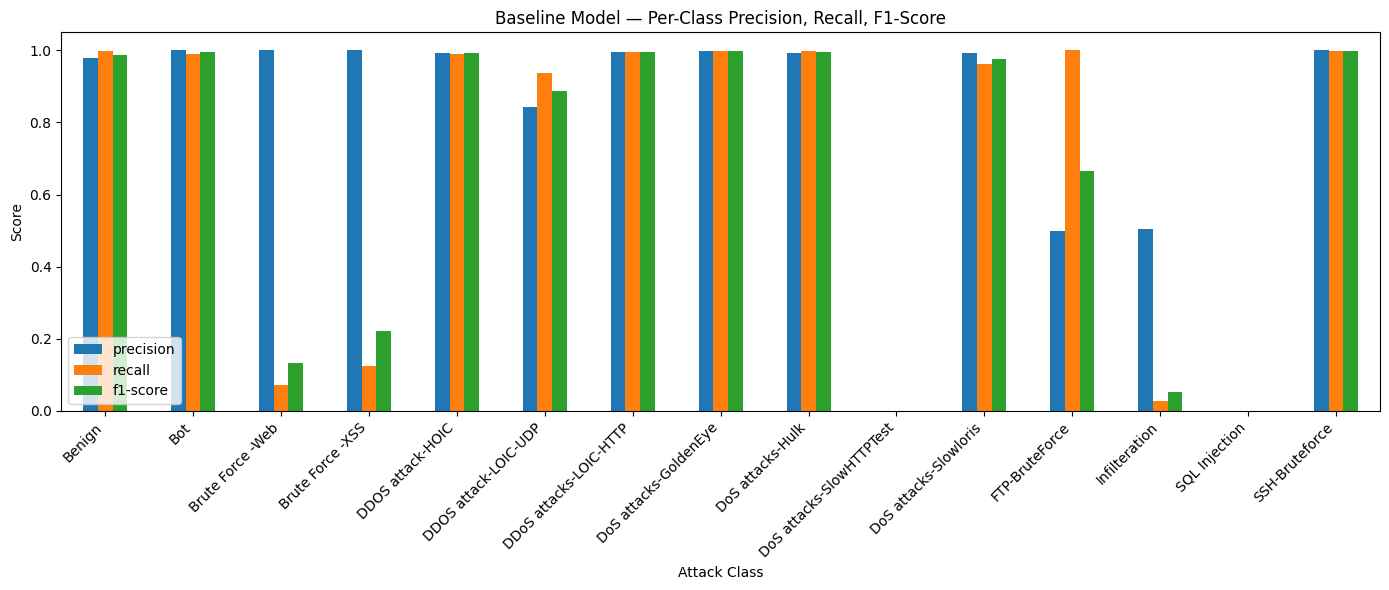

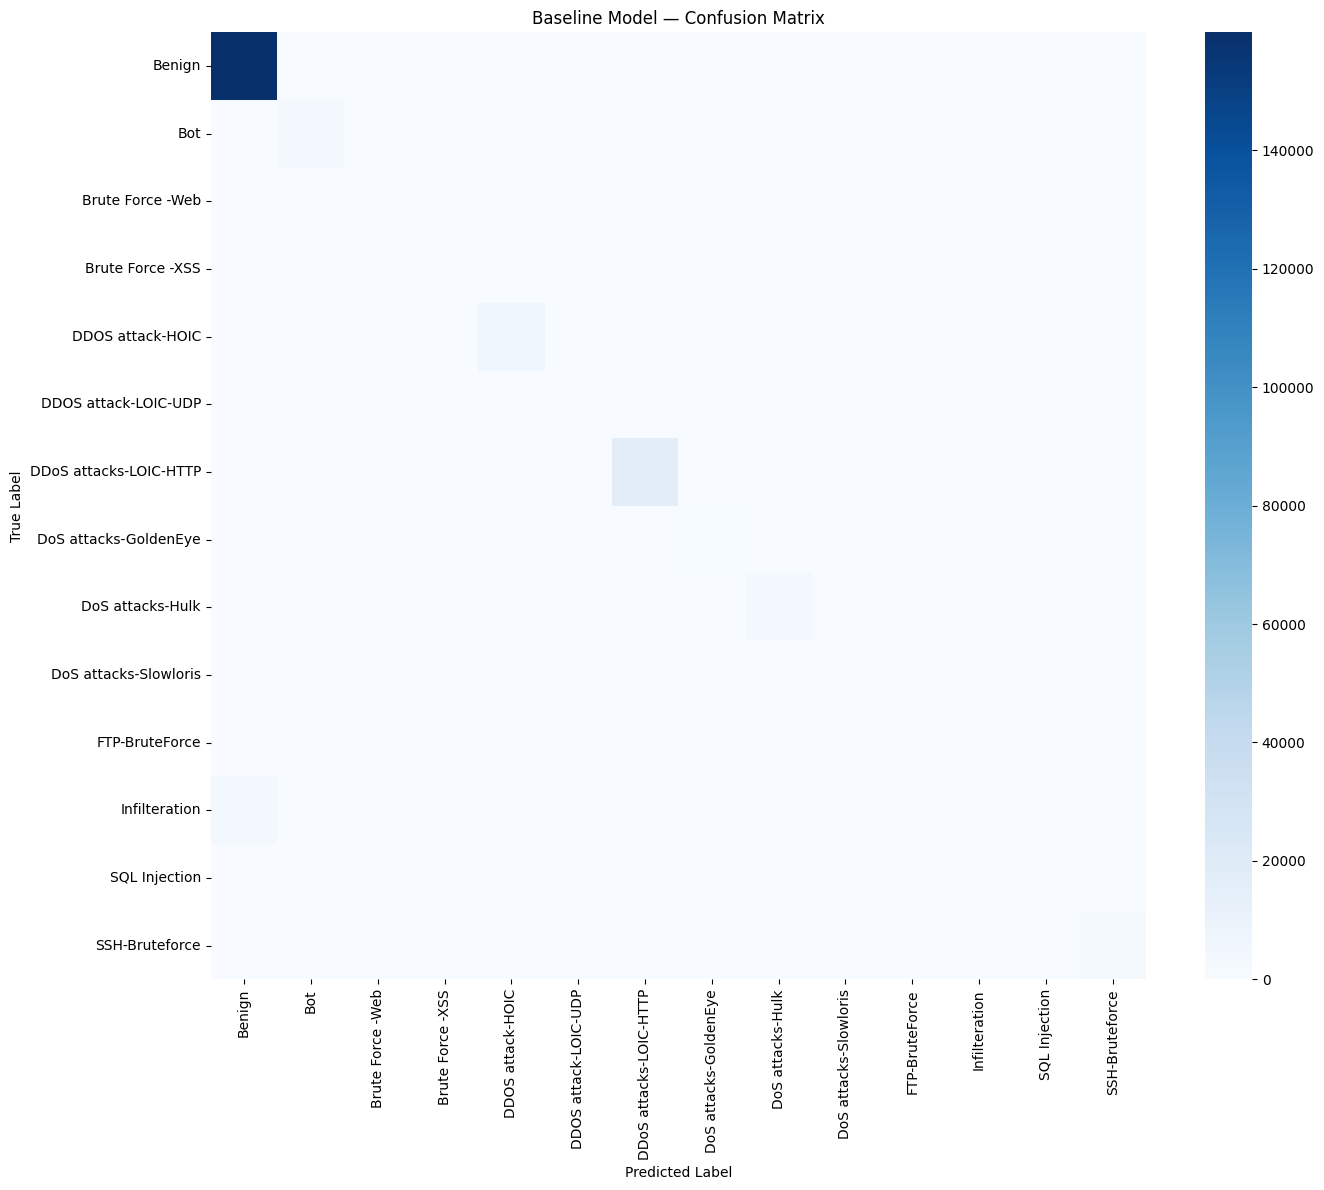

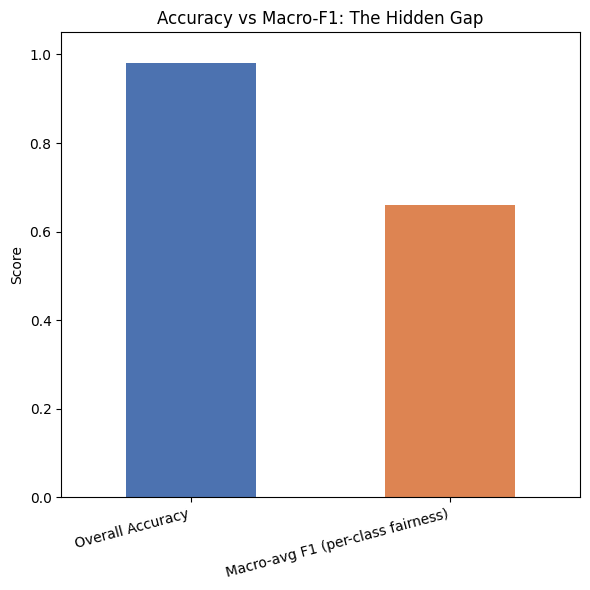

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

# Get the classification report as a dictionary
report_dict = classification_report(y_test_sample, y_pred_baseline, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report_dict).transpose()

# Drop the summary rows for the per-class chart, keep them for a separate table
per_class = report_df.drop(index=['accuracy', 'macro avg', 'weighted avg'])

# ---- Figure 1: Per-class Precision/Recall/F1 bar chart ----
plt.figure(figsize=(14, 6))
per_class[['precision', 'recall', 'f1-score']].plot(kind='bar', figsize=(14, 6))
plt.title('Baseline Model — Per-Class Precision, Recall, F1-Score')
plt.ylabel('Score')
plt.xlabel('Attack Class')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 1.05)
plt.legend(loc='lower left')
plt.tight_layout()
plt.savefig('baseline_per_class_metrics.png', dpi=300)
plt.show()

# ---- Figure 2: Confusion matrix heatmap ----
cm = confusion_matrix(y_test_sample, y_pred_baseline, labels=baseline_model.classes_)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=False, cmap='Blues', xticklabels=baseline_model.classes_, yticklabels=baseline_model.classes_)
plt.title('Baseline Model — Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('baseline_confusion_matrix.png', dpi=300)
plt.show()

# ---- Figure 3: Accuracy vs Macro-F1 comparison (the key motivating chart) ----
plt.figure(figsize=(6, 6))
metrics_compare = pd.Series({
    'Overall Accuracy': report_dict['accuracy'],
    'Macro-avg F1 (per-class fairness)': report_dict['macro avg']['f1-score']
})
metrics_compare.plot(kind='bar', color=['#4C72B0', '#DD8452'])
plt.title('Accuracy vs Macro-F1: The Hidden Gap')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.savefig('accuracy_vs_macrof1.png', dpi=300)
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import glob
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.utils.class_weight import compute_class_weight

# LOAD
path = '/content/drive/MyDrive/2018/'
files = glob.glob(path + '*.parquet')
dfs = []
for f in files:
    df = pd.read_parquet(f)
    df['source_file'] = f.split('/')[-1]
    dfs.append(df)
data = pd.concat(dfs, ignore_index=True)
data = data.replace([np.inf, -np.inf], np.nan).dropna()
print("Loaded:", data.shape)

# SPLIT (by day + attack-type together, so every class appears in train & test)
train_list = []
test_list = []
for (f, label), group in data.groupby(['source_file', 'Label']):
    split_point = int(len(group) * 0.8)
    train_list.append(group.iloc[:split_point])
    test_list.append(group.iloc[split_point:])
train_data3 = pd.concat(train_list, ignore_index=True)
test_data3 = pd.concat(test_list, ignore_index=True)

X_train_cd = train_data3.drop(columns=['Label', 'source_file'])
y_train_cd = train_data3['Label']
X_test_cd = test_data3.drop(columns=['Label', 'source_file'])
y_test_cd = test_data3['Label']

X_train_cd_s = X_train_cd.sample(n=min(150000, len(X_train_cd)), random_state=42).astype('float32')
y_train_cd_s = y_train_cd.loc[X_train_cd_s.index]
X_test_cd_s = X_test_cd.sample(n=min(200000, len(X_test_cd)), random_state=42).astype('float32')
y_test_cd_s = y_test_cd.loc[X_test_cd_s.index]
print(y_train_cd_s.value_counts())

# CLASS WEIGHTS
classes = np.unique(y_train_cd_s)
weights = compute_class_weight('balanced', classes=classes, y=y_train_cd_s)
class_weight_dict = dict(zip(classes, weights))

# TWO-STAGE CASCADE
y_train_binary = y_train_cd_s.apply(lambda v: 'Benign' if v == 'Benign' else 'Attack')
stage1_model = RandomForestClassifier(n_estimators=60, max_depth=20, random_state=42, n_jobs=-1, class_weight='balanced')
stage1_model.fit(X_train_cd_s, y_train_binary)

attack_mask = y_train_cd_s != 'Benign'
X_train_attacks = X_train_cd_s[attack_mask]
y_train_attacks = y_train_cd_s[attack_mask]
stage2_model = RandomForestClassifier(n_estimators=60, max_depth=20, random_state=42, n_jobs=-1, class_weight=class_weight_dict)
stage2_model.fit(X_train_attacks, y_train_attacks)

stage1_pred = stage1_model.predict(X_test_cd_s)
final_predictions = stage1_pred.copy()
attack_rows = stage1_pred == 'Attack'
if attack_rows.sum() > 0:
    stage2_pred = stage2_model.predict(X_test_cd_s[attack_rows])
    final_predictions[attack_rows] = stage2_pred

print("=== NOVELTY (Fixed Split, Higher Accuracy) RESULTS ===")
print(classification_report(y_test_cd_s, final_predictions, zero_division=0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded: (6659532, 79)
Label
Benign                      119961
DDoS attacks-LOIC-HTTP       12945
DDOS attack-HOIC              4538
Bot                           3330
DoS attacks-Hulk              3310
Infilteration                 2611
SSH-Bruteforce                2082
DoS attacks-GoldenEye          948
DoS attacks-Slowloris          199
DDOS attack-LOIC-UDP            54
Brute Force -Web                11
Brute Force -XSS                 4
DoS attacks-SlowHTTPTest         4
FTP-BruteForce                   2
SQL Injection                    1
Name: count, dtype: int64
=== NOVELTY (Fixed Split, Higher Accuracy) RESULTS ===
                          precision    recall  f1-score   support

                  Benign       0.98      1.00      0.99    159699
                     Bot       0.99      1.00      0.99      4459
        Brute Force -Web       1.00   

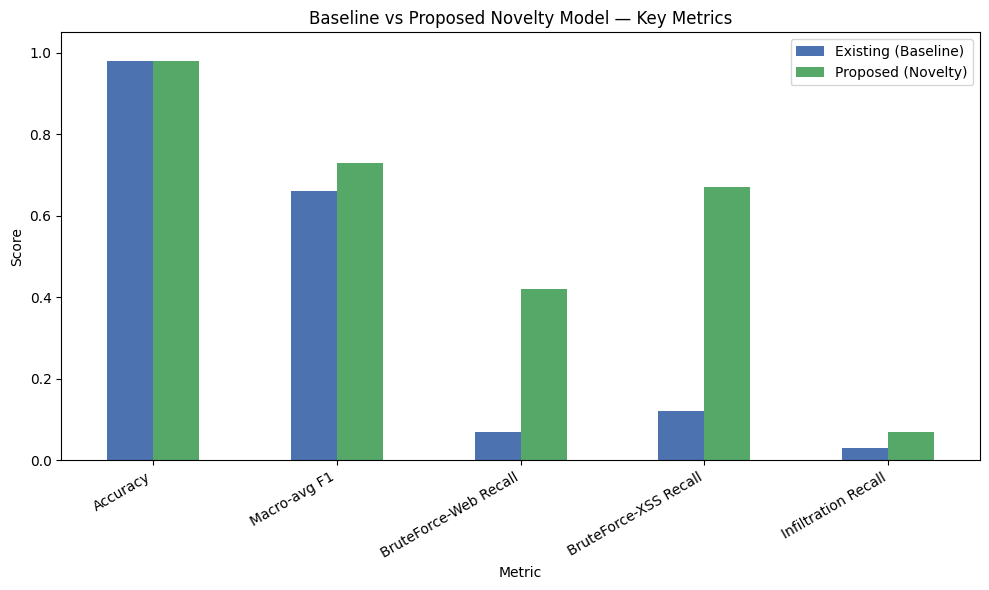

Chart saved to Drive


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Macro-avg F1', 'BruteForce-Web Recall', 'BruteForce-XSS Recall', 'Infiltration Recall'],
    'Baseline': [0.98, 0.66, 0.07, 0.12, 0.03],
    'Novelty': [0.98, 0.73, 0.42, 0.67, 0.07]
})

comparison.plot(x='Metric', kind='bar', figsize=(10,6), color=['#4C72B0', '#55A868'])
plt.title('Baseline vs Proposed Novelty Model — Key Metrics')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha='right')
plt.legend(['Existing (Baseline)', 'Proposed (Novelty)'])
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/2018/novelty_vs_baseline.png', dpi=300)
plt.show()
print("Chart saved to Drive")